# Hedonic Pricing

We often try to predict the price of an asset from its observable characteristics. This is generally called **hedonic pricing**: How do the unit's characteristics determine its market price?

1. Clean the data `pierce_county_house_sales.csv` and perform some EDA and visualization to get to know the data set.
2. Transform your variables - particularly categorical ones - for use in your regression analysis.
3. Implement an 80/20 train-test split. Put the test data aside.
4. Build some simple linear models that include no transformations or interactions. Fit them, and determine their RMSE and $R^2$ on the both the training and test sets. Which of your models does the best?
5. Make partial correlation plots for each of the numeric variables in your model. Do you notice any significant non-linearities? 
6. Include transformations and interactions of your variables, and build a more complex model that reflects your ideas about how the features of the asset determine its value. Determine its RMSE and $R^2$ on the training and test sets. How does the more complex model your build compare to the simpler ones?
7. Summarize your results from 1 to 6. Have you learned anything about overfitting and underfitting, or model selection?
8. Use the `sklearn.linear_model.Lasso` to regularize your model and select the most predictive features. Which does it select? What are the RMSE and $R^2$? We'll cover the Lasso later in detail in class.

---

## *Phase 1: Solution without AI

Complete all questions in the following cells without generative AI. Then commit and push the
notebook before beginning Phase 2.

**Declaration:** I completed this version without generative AI.

**Student(s):** Dylan Wang, Lani Le, Yipeng Cao

**Date:** 11/9/2026

In [1]:
# import all the necessary libraries
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error, r2_score
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline, make_pipeline
from sklearn.preprocessing import OneHotEncoder, PolynomialFeatures, StandardScaler


Shape: (16768, 19)
sale_date                      datetime64[us]
sale_price                              int64
house_square_feet                       int64
attic_finished_square_feet              int64
basement_square_feet                    int64
attached_garage_square_feet             int64
detached_garage_square_feet             int64
fireplaces                              int64
hvac_description                          str
exterior                                  str
interior                                  str
stories                                 int64
roof_cover                                str
year_built                              int64
bedrooms                                int64
bathrooms                               int64
waterfront_type                           str
view_quality                              str
utility_sewer                             str
dtype: object
waterfront_type                16216
view_quality                   15852
roof_cover         

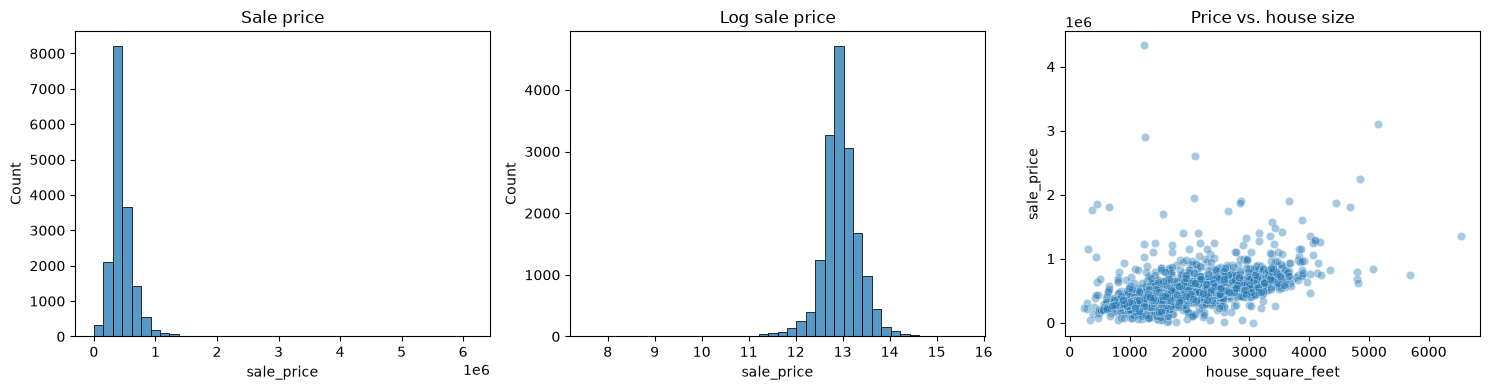

In [2]:
# 1. Clean the data `pierce_county_house_sales.csv` and perform some EDA and visualization to get to know the data set.
df = pd.read_csv('data/pierce_county_house_sales.csv')
# make sale_date a datetime object
df["sale_date"] = pd.to_datetime(df["sale_date"], errors="coerce")
# drop dups
df = df.drop_duplicates()
df = df.dropna(subset=["sale_date"])
df = df[(df["sale_price"] > 0) & (df["house_square_feet"] > 0)].copy()

# print out the shape (16768, 19)
print("Shape:", df.shape)
print(df.dtypes)
print(df.isna().sum().sort_values(ascending=False))
print(df[["sale_price", "house_square_feet", "year_built",
          "bedrooms", "bathrooms"]].describe())

# plot figures to visualize the distribution of sale_price and log(sale_price) 
# and the relationship between house_square_feet and sale_price
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
sns.histplot(df["sale_price"], bins=40, ax=axes[0])
axes[0].set_title("Sale price")
sns.histplot(np.log1p(df["sale_price"]), bins=40, ax=axes[1])
axes[1].set_title("Log sale price")
sns.scatterplot(data=df.sample(min(3000, len(df)), random_state=42),
                x="house_square_feet", y="sale_price", alpha=.4, ax=axes[2])
axes[2].set_title("Price vs. house size")
plt.tight_layout()
plt.show()



In [3]:
# 2. Transform your variables - particularly categorical ones - for use in your regression analysis.
target = "sale_price"
numeric = [
    "house_square_feet", "attic_finished_square_feet", "basement_square_feet",
    "attached_garage_square_feet", "detached_garage_square_feet", "fireplaces",
    "stories", "year_built", "bedrooms", "bathrooms"
]
categorical = [
    "hvac_description", "exterior", "interior", "roof_cover",
    "waterfront_type", "view_quality", "utility_sewer"
]

# changing categorical variables to have values 0 or 1
def make_preprocessor(nums, cats):

    return ColumnTransformer([
        ("num", SimpleImputer(strategy="median"), nums),
        ("cat", make_pipeline(
            SimpleImputer(strategy="constant", fill_value="Missing"),
            OneHotEncoder(handle_unknown="ignore")
        ), cats)
    ])


In [4]:
# 3. Implement an 80/20 train-test split. Put the test data aside.
X = df[numeric + categorical]
y = df[target]
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=42
) # 0.2 because we want 80/20

In [5]:
# 4. Build some simple linear models that include no transformations or interactions. Fit them, and determine their RMSE and $R^2$ on the both the training and test sets. Which of your models does the best?
specs = {
    "Numeric only": numeric,
    "Categorical only": categorical,
    "Both numeric and categorical": numeric + categorical,
}
models = {}
rows = []

# for each model spec, create a pipeline with a preprocessor and lm 
# fit the lm for each spec, train them, and 
# eventually calculate the metrics (rmse and r_squared) 
# for both train and test sets
for name, cols in specs.items():
    nums = [c for c in cols if c in numeric]
    cats = [c for c in cols if c in categorical]
    model = Pipeline([
        ("prep", make_preprocessor(nums, cats)),
        ("reg", LinearRegression())
    ])
    model.fit(X_train[cols], y_train)
    models[name] = model

    for split_name, x, actual in [
        ("Train", X_train[cols], y_train),
        ("Test", X_test[cols], y_test),
    ]:
        pred = model.predict(x)
        rows.append({
            "Model": name,
            "Split": split_name,
            "RMSE": np.sqrt(mean_squared_error(actual, pred)),
            "R2": r2_score(actual, pred),
        })

simple_results = pd.DataFrame(rows)
print(simple_results.round(3))
print("Best simple model by test RMSE:",
      simple_results.query("Split == 'Test'").sort_values("RMSE").iloc[0]["Model"])


                          Model  Split        RMSE     R2
0                  Numeric only  Train  185345.196  0.401
1                  Numeric only   Test  170421.990  0.411
2              Categorical only  Train  192675.277  0.353
3              Categorical only   Test  185517.354  0.302
4  Both numeric and categorical  Train  161581.020  0.545
5  Both numeric and categorical   Test  155461.334  0.510
Best simple model by test RMSE: Both numeric and categorical


As we can see from the result, the best model is the one that combines both numeric and categorical values. This model has the highest R^2 (model explains variance well, in this case over 50%) and lowest RMSE (smaller average error).

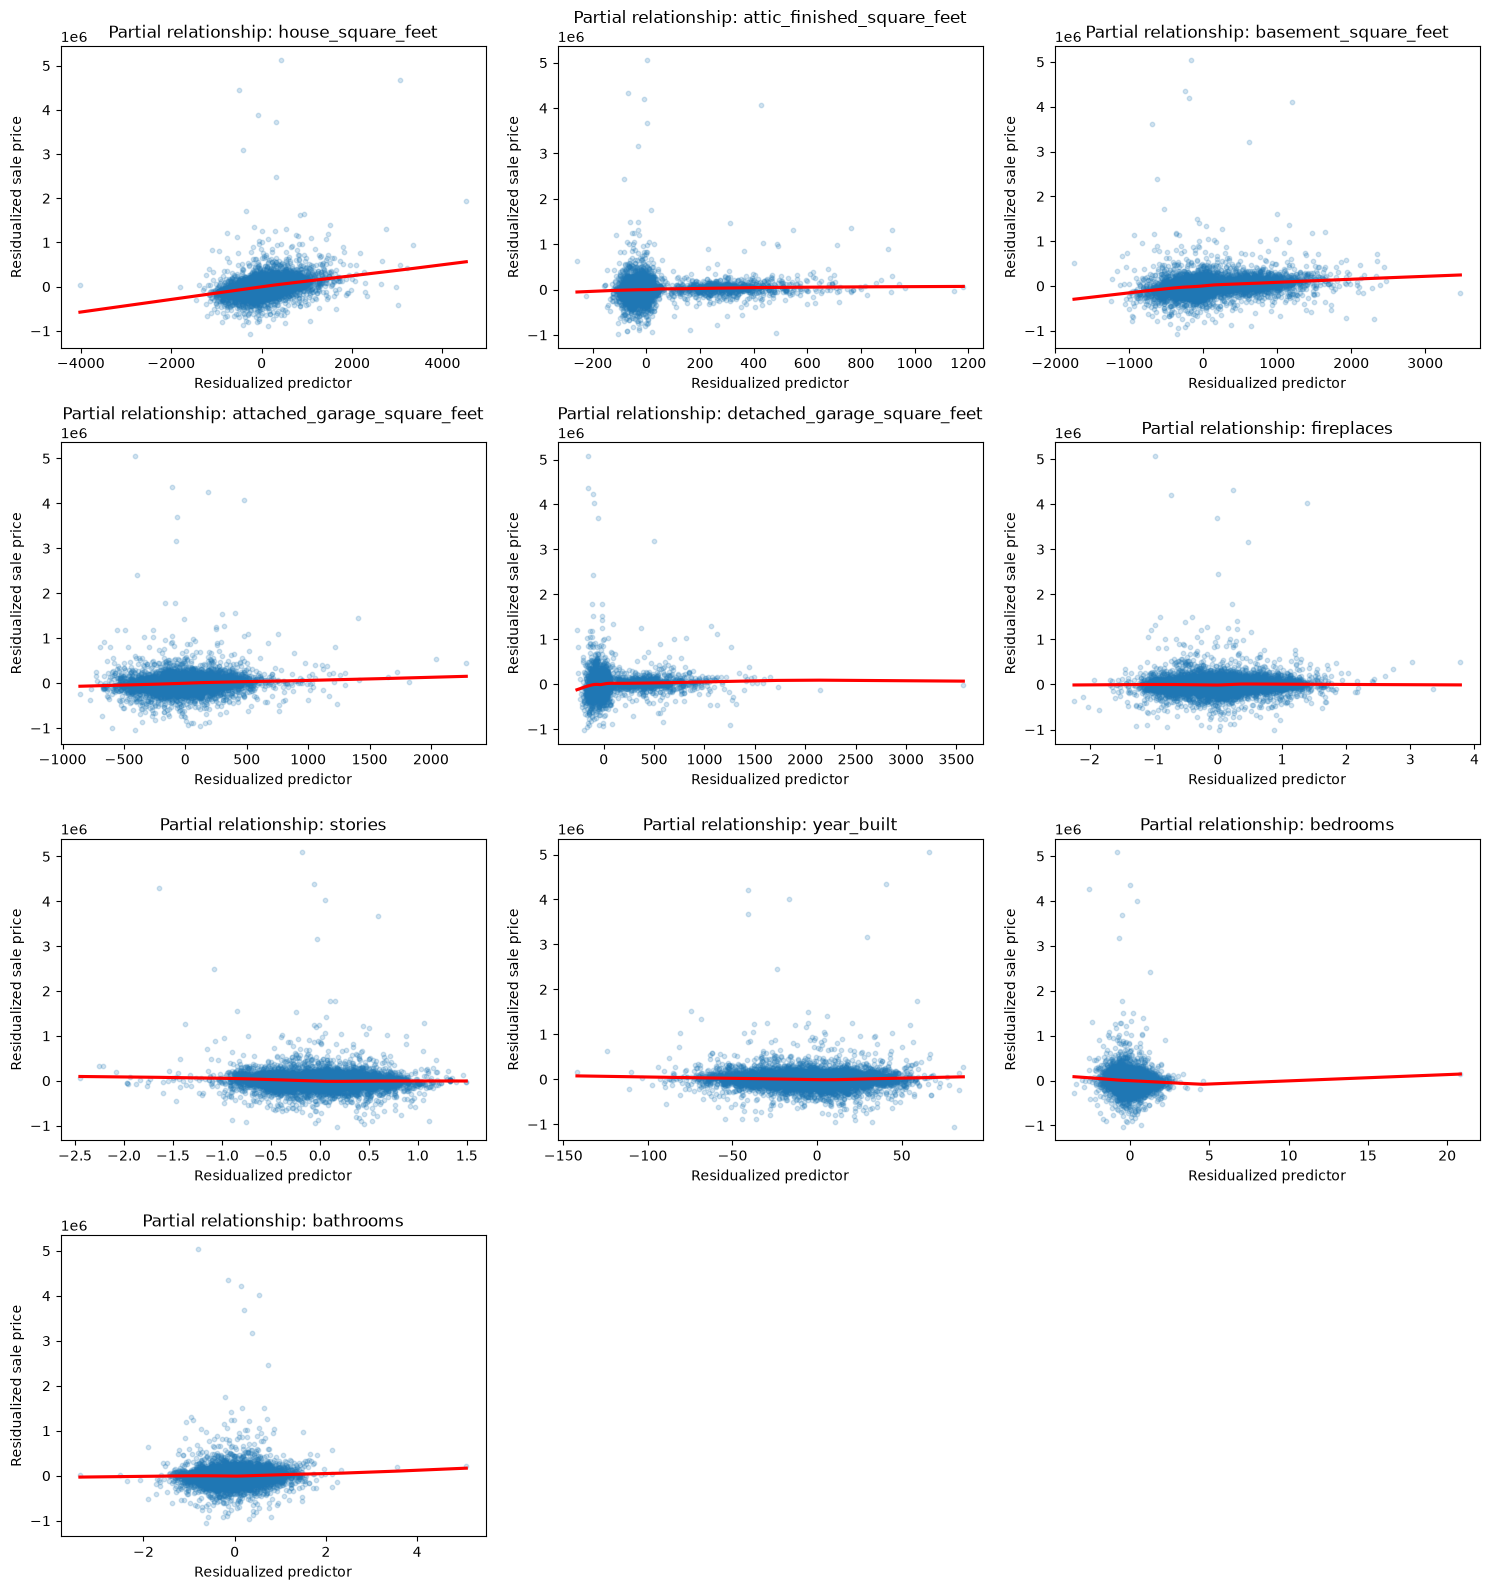

In [6]:
# 5. Make partial correlation plots for each of the numeric variables in your model. Do you notice any significant non-linearities? 
import matplotlib.pyplot as plt
fig, axes = plt.subplots(4, 3, figsize=(15, 16))
axes = axes.ravel()

for i, feature in enumerate(numeric):
    controls = [c for c in numeric + categorical if c != feature]
    control_nums = [c for c in controls if c in numeric]
    control_cats = [c for c in controls if c in categorical]

    prep = make_preprocessor(control_nums, control_cats)
    Z = prep.fit_transform(X_train[controls])

    y_resid = y_train - LinearRegression().fit(Z, y_train).predict(Z)
    x_resid = X_train[feature] - LinearRegression().fit(
        Z, X_train[feature].fillna(X_train[feature].median())
    ).predict(Z)

    sns.regplot(x=x_resid, y=y_resid, lowess=True,
                scatter_kws={"alpha": .2, "s": 10},
                line_kws={"color": "red"}, ax=axes[i])
    axes[i].set_title(f"Partial relationship: {feature}")
    axes[i].set_xlabel("Residualized predictor")
    axes[i].set_ylabel("Residualized sale price")

for ax in axes[len(numeric):]:
    ax.remove()
plt.tight_layout()
plt.show()


There exists some non-linearities, such as attic finished_square_feet (most buyers probably do not care about if it is finished, so it shows little correlation), detached_garage_square_feet (most homes have 0 so it shows as non-linear), and bedrooms (Bedrooms may look nonlinear because bedroom count is discrete and overlaps with house size and bathrooms, while homes with unusually many bedrooms are rare).

In [7]:
# 6. Include transformations and interactions of your variables, and build a more complex model that reflects your ideas about how the features of the asset determine its value. Determine its RMSE and $R^2$ on the training and test sets. How does the more complex model your build compare to the simpler ones?
def add_engineered_features(frame):
    out = frame.copy()
    # break the date into yr, month
    out["sale_year"] = out["sale_date"].dt.year
    out["sale_month"] = out["sale_date"].dt.month
    # the house age is the difference between the sale year and the year built
    out["house_age"] = out["sale_year"] - out["year_built"]
    out["total_area"] = (
        out["house_square_feet"] + out["attic_finished_square_feet"]
        + out["basement_square_feet"]
    ) # create a new column of total area by summing the other cols
    out["total_garage_area"] = (
        out["attached_garage_square_feet"] + out["detached_garage_square_feet"]
    ) # total_garage
    return out.drop(columns="sale_date")

X_complex = add_engineered_features(df)
complex_numeric = numeric + [
    "sale_year", "sale_month", "house_age", "total_area", "total_garage_area"
]
complex_categorical = categorical
complex_cols = complex_numeric + complex_categorical

def make_complex_preprocessor():
    return ColumnTransformer([
        ("num", make_pipeline(
            SimpleImputer(strategy="median"),
            PolynomialFeatures(degree=2, interaction_only=True, include_bias=False)
        ), complex_numeric),
        ("cat", make_pipeline(
            SimpleImputer(strategy="constant", fill_value="Missing"),
            OneHotEncoder(handle_unknown="ignore")
        ), complex_categorical)
    ])

Xc_train, Xc_test, yc_train, yc_test = train_test_split(
    X_complex[complex_cols], y, test_size=0.20, random_state=42
)
complex_model = Pipeline([
    ("prep", make_complex_preprocessor()),
    ("reg", LinearRegression())
])
complex_model.fit(Xc_train, yc_train)

for split_name, x, actual in [
    ("Train", Xc_train, yc_train),
    ("Test", Xc_test, yc_test),
]:
    pred = complex_model.predict(x)
    print(f"Complex model {split_name}: "
          f"RMSE={np.sqrt(mean_squared_error(actual, pred)):.2f}, "
          f"R2={r2_score(actual, pred):.3f}")



Complex model Train: RMSE=175272.92, R2=0.464
Complex model Test: RMSE=162474.97, R2=0.464


We engineered additional features, including total house area, sale year and month, house age, and total garage area, and added pairwise interactions to build a more complex model. However, the complex model performed worse than the simple model with both numeric and categorical predictors: its test \(R^2\) fell from 0.510 to 0.464, and its test RMSE rose from about $155,461 to $162,475. This suggests that the added features and interactions did not improve predictions; because training performance also declined, the results do not indicate classic overfitting.

7. Summarize your results from 1 to 6. Have you learned anything about overfitting and underfitting, or model selection?

After cleaning and exploring the data, I found that the dataset contains both numeric and categorical features, with much of the missing data in waterfront_type and view_quality. I one-hot encoded the categorical variables and used an 80/20 train-test split. The model with both numeric and categorical predictors performed best among the simple models, with a test RMSE of about $155,461 and test R^2 of 0.510. The partial regression plots looked mostly linear or weak; detached garage area showed some flattening, while the curve for bedrooms was less clear because few homes had high residualized bedroom counts. Adding engineered features and interactions did not improve performance: the complex model’s test RMSE increased to about $162,475 and its test R^2 fell to 0.464. The simple model had a modest train-test gap, but the results show no severe overfitting. They also show that adding complexity does not guarantee better predictions, so I would select the simpler model based on its stronger test performance.

In [10]:
# 8. Use the `sklearn.linear_model.Lasso` to regularize your model and select the most predictive features. Which does it select? What are the RMSE and $R^2$? We'll cover the Lasso later in detail in class.
from sklearn.linear_model import LassoCV

prep = complex_model.named_steps["prep"]
Xctr = prep.transform(Xc_train)
Xcte = prep.transform(Xc_test)

scaler = StandardScaler(with_mean=False)
Xctr_scaled = scaler.fit_transform(Xctr)
Xcte_scaled = scaler.transform(Xcte)

lasso = LassoCV(cv=5, max_iter=20000)
lasso.fit(Xctr_scaled, yc_train)

selected = pd.Series(
    lasso.coef_,
    index=prep.get_feature_names_out()
)
print(selected[selected.abs() > 1e-8].sort_values(key=abs, ascending=False))

pred = lasso.predict(Xcte_scaled)
print(
    f"Test RMSE: {np.sqrt(mean_squared_error(yc_test, pred)):.2f}, "
    f"R_squared: {r2_score(yc_test, pred):.3f}"
)

cat__waterfront_type_WF Salt                                   66542.086168
num__house_square_feet year_built                              60095.608737
num__fireplaces total_area                                     39550.855153
cat__waterfront_type_WF Lake                                   36052.619849
cat__exterior_Missing                                          34183.982195
                                                                   ...     
cat__waterfront_type_Missing                                    -470.574121
cat__view_quality_View Lim +                                     221.755313
num__fireplaces sale_month                                       119.243096
num__house_age total_area                                        -40.624950
num__attic_finished_square_feet detached_garage_square_feet       13.441331
Length: 92, dtype: float64
Test RMSE: 149503.82, R_squared: 0.547


## *Phase 2: AI-assisted Revision
Keep Phase 1 frozen.

- **Phase 1 commit SHA ID:** [To be provided]
- **AI tool and model used:** [To be provided]

### *Prompts used

1. [Paste prompt]
2. [Paste follow-up prompt]

### *AI-proposed changes


[Paste the AI's concise numbered list verbatim.]

1. ...
2. ...

### *Evaluation of AI suggestions


| Change | Decision | Reason and verification |
|---|---|---|
| 1 | Accept / modify / reject | ... |
| 2 | Accept / modify / reject | ... |

### *AI-assisted solution in full
After the evaluation of AI suggestions, incorporate the accepted revisions into your Phase 1 solution and provide the final Phase 2 solution in full in the following cells.

In [9]:
# Your Phase 2 solution to the problem goes here.


### *Reflection on AI assistance
In your own words without generative AI.

[In 150–300 words, describe the main improvements, AI mistakes or limitations, how the final solution was verified, and any remaining concerns.]